<a href="https://colab.research.google.com/github/mdzubayereashraf/Ostad-AI-Engineering-Course-Assignments/blob/main/Assignmen_No_16(People_Flow_Detection_using_Object_Tracking_%26amp%3B_Heatmap_Visualization_%7C%7C_Object_Tracking_Project).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# People Flow Detection Using Object Tracking and Heatmap Visualization

## Project Overview

This project detects and tracks people in a video using a pretrained YOLO model and ByteTrack. It counts people crossing two horizontal lines to estimate incoming and outgoing movement. A heatmap is also generated to visualize areas where people frequently appear.

## Objectives

* Detect people using a pretrained YOLO model.
* Track detected people using unique IDs.
* Count people entering and leaving based on line-crossing events.
* Generate a heatmap of people's movement or presence.
* Save the processed video and heatmap as output files.


### **Install Required Libraries**

In [2]:
!pip install -q ultralytics opencv-python-headless matplotlib numpy

### **Video Download**

In [3]:
import os
import urllib.request

VIDEO_URL = "https://media.roboflow.com/supervision/video-examples/people-walking.mp4"
VIDEO_PATH = "/content/people-walking.mp4"

urllib.request.urlretrieve(VIDEO_URL, VIDEO_PATH)

print("Video downloaded:", os.path.exists(VIDEO_PATH))
print("File size (MB):", round(os.path.getsize(VIDEO_PATH) / (1024**2), 2))

Video downloaded: True
File size (MB): 7.25


### **Inspect the Video and Define Counting Lines**

First, we inspect the video's width, height, frame rate, and total number of frames.

We then define two horizontal counting lines:

**Upper line:** One-third of the video height.
**Lower line:** Two-thirds of the video height.

The lines are displayed on a sample frame to verify their positions before processing the complete video.

Width: 1920
Height: 1080
FPS: 25.0
Frame count: 341
Upper line y-coordinate: 360
Lower line y-coordinate: 720


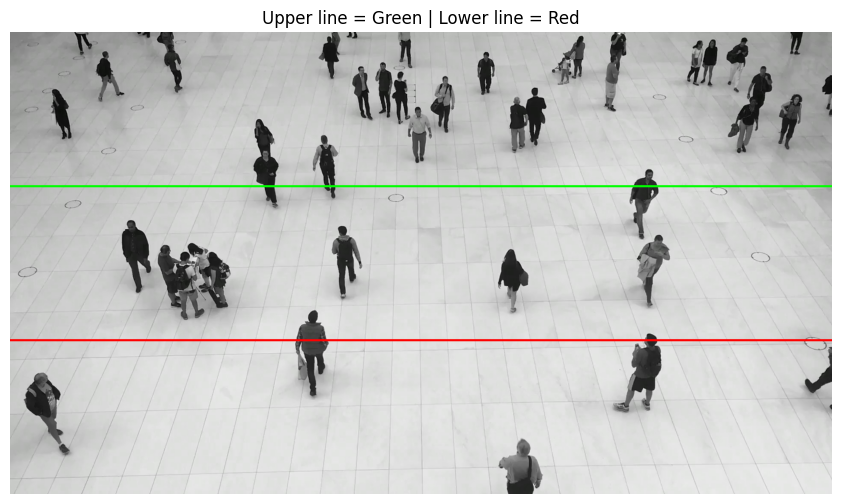

In [4]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Could not open the video.")

WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
FPS = cap.get(cv2.CAP_PROP_FPS)
FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

cap.release()

# Horizontal counting lines
UPPER_LINE = HEIGHT // 3
LOWER_LINE = (2 * HEIGHT) // 3

print("Width:", WIDTH)
print("Height:", HEIGHT)
print("FPS:", FPS)
print("Frame count:", FRAME_COUNT)
print("Upper line y-coordinate:", UPPER_LINE)
print("Lower line y-coordinate:", LOWER_LINE)

# Preview the two lines on a video frame
cap = cv2.VideoCapture(VIDEO_PATH)
success, frame = cap.read()
cap.release()

if success:
    cv2.line(frame, (0, UPPER_LINE),
             (WIDTH, UPPER_LINE), (0, 255, 0), 3)

    cv2.line(frame, (0, LOWER_LINE),
             (WIDTH, LOWER_LINE), (0, 0, 255), 3)

    plt.figure(figsize=(12, 6))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Upper line = Green | Lower line = Red")
    plt.axis("off")
    plt.show()

### **Load the Pretrained YOLO Model**

We use the pretrained YOLOv8n model to detect people in each video frame. The model is lightweight and suitable for object detection experiments.

We restrict detection to the person class and use ByteTrack to maintain tracking IDs across consecutive frames.


In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO model loaded successfully.
